# Size & Fit Analysis: Which products run small or large, and what should we change?

**Business question:** Which product categories and sizes have the highest fit-mismatch
rate, who is affected, and what sizing or grading changes would reduce return risk?

**Data:** Rent the Runway fit dataset (Misra et al., McAuley Lab, UCSD).
File: `renttherunway_final_data.json` (one JSON record per line; ~192K reviews). Columns: `fit` (small / fit / large), `size`,
`height`, `weight`, `bust size`, `body type`, `category`, `rented for`, `rating`,
`review_text`, `review_summary`, `review_date`, `age`, `item_id`, `user_id`.

**Important framing:** this dataset has no return flag. A customer saying an item ran
small or large is the *fit-mismatch* signal, used here as a proxy for return risk.
The report states this assumption rather than hiding it.


In [1]:
import os, re, json, gzip, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, f1_score, roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

DATA_PATH = "renttherunway_final_data.json"   # also works with the .json.gz version
OUT_DIR = "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Minimum reviews in a category x size cell before we trust its rate
MIN_CELL_N = 40
# A flag needs statistical AND practical significance (huge categories make tiny gaps 'significant')
MIN_EFFECT = 0.03   # at least 3 percentage points above the overall rate

## 1. Load data
One JSON object per line. Some rows are missing height/weight/bust size, which we handle below.

In [2]:
def load_real(path):
    rows = []
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return pd.DataFrame(rows)


df_raw = load_real(DATA_PATH)
print(df_raw.shape)
df_raw.head(3)

(192544, 15)


,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36,"June 18, 2013"
2,fit,360448,NaN,1063761,NaN,10,party,This hugged in all the right places! It was a ...,NaN,It was a great time to celebrate the (almost) ...,sheath,"5' 4""",4,116,"December 14, 2015"


## 2. Clean and engineer features

In [3]:
def parse_height(s):
    m = re.match(r"\s*(\d+)'\s*(\d+)", str(s))
    return int(m.group(1)) * 12 + int(m.group(2)) if m else np.nan

def parse_weight(s):
    m = re.search(r"(\d+)", str(s))
    return float(m.group(1)) if m else np.nan

df = df_raw.copy()
df = df[df["fit"].isin(["small", "fit", "large"])].copy()
df["height_in"] = df["height"].map(parse_height)
df["weight_lb"] = df["weight"].map(parse_weight)
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["size"] = pd.to_numeric(df["size"], errors="coerce")
df["review_date"] = pd.to_datetime(df["review_date"], errors="coerce")

# Remove implausible values (data-entry errors exist in the real file)
df.loc[~df["height_in"].between(54, 80), "height_in"] = np.nan
df.loc[~df["weight_lb"].between(80, 300), "weight_lb"] = np.nan
df.loc[~df["age"].between(16, 80), "age"] = np.nan
df = df[df["size"].between(0, 60)]

df["bmi"] = 703 * df["weight_lb"] / df["height_in"] ** 2
df["category"] = df["category"].fillna("unknown").str.lower().str.strip()
df["review_text"] = df["review_text"].fillna("").str.lower()

# Size buckets (US numeric sizing)
bins = [-1, 2, 6, 10, 14, 20, 60]
labels = ["0-2 (XS)", "4-6 (S)", "8-10 (M)", "12-14 (L)", "16-20 (XL)", "22+ (XXL+)"]
df["size_bucket"] = pd.cut(df["size"], bins=bins, labels=labels)

df["is_small"] = (df["fit"] == "small").astype(int)
df["is_large"] = (df["fit"] == "large").astype(int)
df["mismatch"] = (df["fit"] != "fit").astype(int)

# Keep categories with enough data to analyze; lump the long tail
cat_counts = df["category"].value_counts()
keep = cat_counts[cat_counts >= 300].index
df["category_grp"] = np.where(df["category"].isin(keep), df["category"], "other")

print(df.shape)
print(df["fit"].value_counts(normalize=True).round(3))
print(df[["height_in", "weight_lb", "bmi", "age", "size"]].describe().round(1))

(192544, 23)
fit
fit      0.738
small    0.134
large    0.128
Name: proportion, dtype: float64
       height_in  weight_lb       bmi       age      size
count   191867.0   162553.0  162109.0  191400.0  192544.0
mean        65.3      137.4      22.7      33.8      12.2
std          2.7       21.9       3.4       7.9       8.5
min         54.0       80.0      14.6      16.0       0.0
25%         63.0      123.0      20.4      29.0       8.0
50%         65.0      135.0      22.0      32.0      12.0
75%         67.0      148.0      24.1      37.0      16.0
max         78.0      300.0      54.5      78.0      58.0


## 3. Mine fit signals from review text
Rule-based extraction first (transparent and fast). The `fit` label is the ground truth,
so we also check how well the text rules agree with it. A strong agreement shows the same
rules would work on datasets that have text but no label.

The text also tells us *where* a garment fails (shoulders, bust, waist, hips, length),
which the label alone cannot.

In [4]:
# Phrases that describe the ITEM's sizing. "sized up" / "sized down" are deliberately excluded:
# renters often sized up on purpose and then reported the item fit.
SMALL_PAT = (r"runs? (?:a (?:bit|little) |slightly )?small|ran (?:a (?:bit|little) |slightly )?small|too small|too tight|"
             r"a bit tight|little tight|slightly tight|bit snug|too snug|tight (?:in|across|around|on) ")
LARGE_PAT = (r"runs? (?:a (?:bit|little) |slightly )?(?:large|big)|ran (?:a (?:bit|little) |slightly )?(?:large|big)|"
             r"too big|too large|too loose|a (?:bit|little) (?:big|loose)|baggy|huge on me|loose (?:in|around)|gaping")
NEG_BEFORE = re.compile(r"(?:not|n't|never|no|nor|without)\W+(?:\w+\W+){0,2}$")

def has_phrase(pattern, text):
    """True if the phrase appears and is not negated ("not too tight", "didn't run small")."""
    for m in re.finditer(pattern, text):
        if not NEG_BEFORE.search(text[max(0, m.start() - 25):m.start()]):
            return True
    return False

df["txt_small"] = [int(has_phrase(SMALL_PAT, t)) for t in df["review_text"]]
df["txt_large"] = [int(has_phrase(LARGE_PAT, t)) for t in df["review_text"]]

OTHER_PATTERNS = {
    "len_short":     r"too short|a bit short|little short|shorter than|hem(?:med)? (?:was )?too high",
    "len_long":      r"too long|needed (?:to be )?hem|needed hemming|hem(?:med)? it|dragged|tripping|trip over",
    "area_shoulder": r"shoulder",
    "area_bust":     r"bust|chest|boob|cleavage",
    "area_waist":    r"waist",
    "area_hips":     r"\bhip",
    "area_arm":      r"\barm|sleeve",
}
for name, pat in OTHER_PATTERNS.items():
    df[name] = df["review_text"].str.contains(pat, regex=True).astype(int)

# Combined "text says small/large" signal
df["text_dir"] = np.select(
    [(df.txt_small == 1) & (df.txt_large == 0), (df.txt_large == 1) & (df.txt_small == 0)],
    ["small", "large"], default="none")

mentioned = df[df.text_dir != "none"]
print(f"Reviews with a directional fit phrase: {len(mentioned):,} ({len(mentioned)/len(df):.1%})")
print("\nWhat the customer's own fit label says, given what the review text says (rows = text):")
print(pd.crosstab(mentioned["text_dir"], mentioned["fit"], normalize="index").round(3))
for c, col in [("small", "txt_small"), ("large", "txt_large")]:
    print(f"Recall of text rule for label '{c}': {df.loc[df.fit == c, col].mean():.1%}")

# How often does the text flag a sizing problem while the customer's own fit label is 'fit'?
hidden = ((df.text_dir != "none") & (df.fit == "fit")).mean()
print(f"\nShare of ALL reviews where text says the item runs small/large but the customer reports 'fit': {hidden:.1%}")

Reviews with a directional fit phrase: 35,974 (18.7%)

What the customer's own fit label says, given what the review text says (rows = text):
fit         fit  large  small
text_dir                     
large     0.419  0.530  0.051
small     0.484  0.029  0.487
Recall of text rule for label 'small': 37.5%
Recall of text rule for label 'large': 39.7%

Share of ALL reviews where text says the item runs small/large but the customer reports 'fit': 8.5%


**How to read this:** the text rule and the label are not the same measurement. When text says
an item "runs small" but the label is `fit`, the customer usually adjusted (sized up) and it worked.
The text therefore captures the **item's sizing tendency**, while the label captures the
**customer's outcome**. Both matter: items whose tendency forces customers to guess their size
carry hidden risk even when this reviewer got lucky.

## 4. Fit-mismatch rates by category and size
Rates come with Wilson 95% confidence intervals so small cells don't produce false alarms.
A cell is flagged only if its **lower** confidence bound exceeds the overall rate **and** the gap is at least `MIN_EFFECT` (3 points), so big categories don't flag on trivial differences.

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

overall = df[["mismatch", "is_small", "is_large"]].mean()
print("Overall rates:\n", overall.round(3))

def rate_table(data, by):
    g = data.groupby(by, observed=True).agg(
        n=("mismatch", "size"), mismatch=("mismatch", "sum"),
        small=("is_small", "sum"), large=("is_large", "sum")).reset_index()
    g["mismatch_rate"] = g["mismatch"] / g["n"]
    g["small_rate"] = g["small"] / g["n"]
    g["large_rate"] = g["large"] / g["n"]
    ci = g.apply(lambda r: wilson(r["mismatch"], r["n"]), axis=1, result_type="expand")
    g["mm_lo"], g["mm_hi"] = ci[0], ci[1]
    ci_s = g.apply(lambda r: wilson(r["small"], r["n"]), axis=1, result_type="expand")
    g["small_lo"] = ci_s[0]
    ci_l = g.apply(lambda r: wilson(r["large"], r["n"]), axis=1, result_type="expand")
    g["large_lo"] = ci_l[0]
    return g

by_cat = rate_table(df, "category_grp").sort_values("mismatch_rate", ascending=False)
by_cat["flag_high"] = (by_cat["mm_lo"] > overall["mismatch"]) & (by_cat["mismatch_rate"] - overall["mismatch"] >= MIN_EFFECT)
print("\nBy category:")
print(by_cat.round(3).to_string(index=False))

by_cell = rate_table(df, ["category_grp", "size_bucket"])
by_cell = by_cell[by_cell["n"] >= MIN_CELL_N].copy()
by_cell["flag_small"] = (by_cell["small_lo"] > overall["is_small"]) & (by_cell["small_rate"] - overall["is_small"] >= MIN_EFFECT)
by_cell["flag_large"] = (by_cell["large_lo"] > overall["is_large"]) & (by_cell["large_rate"] - overall["is_large"] >= MIN_EFFECT)
by_cell["flag_mismatch"] = (by_cell["mm_lo"] > overall["mismatch"]) & (by_cell["mismatch_rate"] - overall["mismatch"] >= MIN_EFFECT)
print(f"\nCategory x size cells analyzed (n >= {MIN_CELL_N}): {len(by_cell)}; "
      f"flagged for mismatch: {int(by_cell.flag_mismatch.sum())}")

Overall rates:
 mismatch    0.262
is_small    0.134
is_large    0.128
dtype: float64

By category:
category_grp     n  mismatch  small  large  mismatch_rate  small_rate  large_rate  mm_lo  mm_hi  small_lo  large_lo  flag_high
        coat   980       396     36    360          0.404       0.037       0.367  0.374  0.435     0.027     0.338       True
       pants   422       159     43    116          0.377       0.102       0.275  0.332  0.424     0.077     0.234       True
       shift  5365      1698    806    892          0.316       0.150       0.166  0.304  0.329     0.141     0.157       True
       skirt  1531       480    266    214          0.314       0.174       0.140  0.291  0.337     0.156     0.123       True
  shirtdress   729       222     51    171          0.305       0.070       0.235  0.272  0.339     0.054     0.205       True
       other  3107       943    263    680          0.304       0.085       0.219  0.288  0.320     0.075     0.205       True
        down

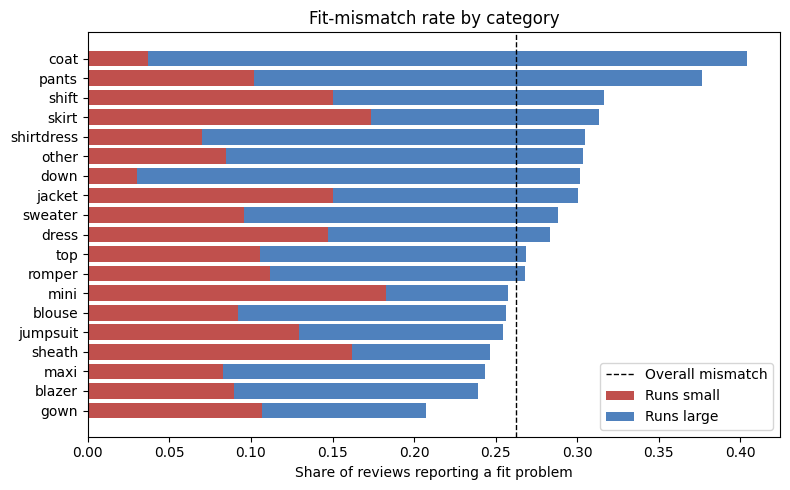

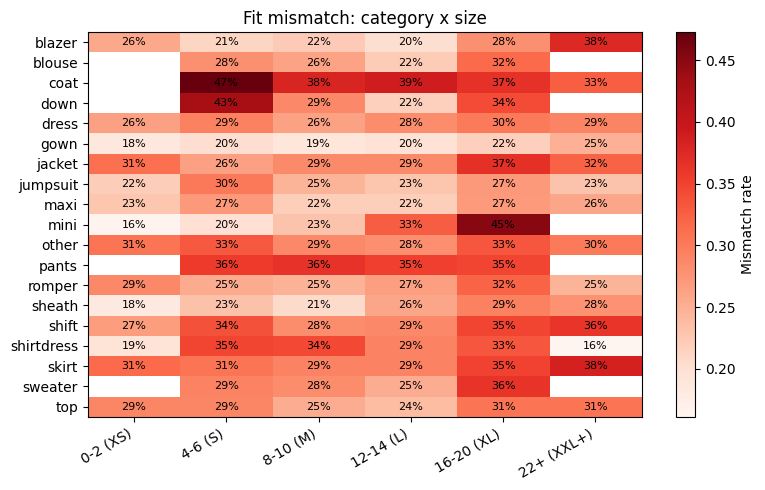

In [6]:
# Figure 1: mismatch rate by category with CI
fig, ax = plt.subplots(figsize=(8, 5))
plot = by_cat.sort_values("mismatch_rate")
ax.barh(plot["category_grp"], plot["small_rate"], label="Runs small", color="#c0504d")
ax.barh(plot["category_grp"], plot["large_rate"], left=plot["small_rate"], label="Runs large", color="#4f81bd")
ax.axvline(overall["mismatch"], color="k", ls="--", lw=1, label="Overall mismatch")
ax.set_xlabel("Share of reviews reporting a fit problem")
ax.set_title("Fit-mismatch rate by category")
ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_mismatch_by_category.png", dpi=150); plt.show()

# Figure 2: heatmap of mismatch by category x size
pivot = by_cell.pivot(index="category_grp", columns="size_bucket", values="mismatch_rate")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns, rotation=30, ha="right")
ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Mismatch rate"); ax.set_title("Fit mismatch: category x size")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_heatmap_category_size.png", dpi=150); plt.show()

## 5. Size relative to body
Raw size and body measurements are highly correlated (r ~ 0.75), which muddies model
coefficients. Instead we compute **size vs. body**: how much bigger or smaller a size the
reviewer rented than is typical for someone of their height and BMI (regression residual).

                svb_group     n  small  large  mismatch
much smaller than typical 32495  0.065  0.213     0.279
                  smaller 32590  0.088  0.134     0.222
                  typical 32182  0.115  0.114     0.228
                   bigger 32434  0.159  0.096     0.255
 much bigger than typical 32408  0.247  0.087     0.334


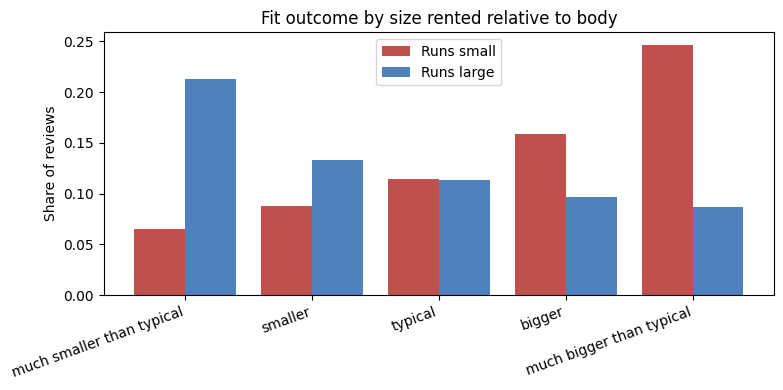

In [7]:
body = df.dropna(subset=["bmi", "height_in"]).copy()
fit_rows = body[body["size"] <= 40]
Xb = np.column_stack([np.ones(len(fit_rows)), fit_rows["bmi"], fit_rows["height_in"]])
coef = np.linalg.lstsq(Xb, fit_rows["size"].values, rcond=None)[0]
df["size_vs_body"] = np.nan
df.loc[body.index, "size_vs_body"] = body["size"] - (coef[0] + coef[1] * body["bmi"] + coef[2] * body["height_in"])
df["svb_group"] = pd.qcut(df["size_vs_body"], 5, labels=["much smaller than typical", "smaller", "typical",
                                                          "bigger", "much bigger than typical"])
svb = df.groupby("svb_group", observed=True).agg(n=("fit", "size"), small=("is_small", "mean"),
                                                 large=("is_large", "mean"), mismatch=("mismatch", "mean")).reset_index()
print(svb.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(svb))
ax.bar(x - 0.2, svb["small"], 0.4, label="Runs small", color="#c0504d")
ax.bar(x + 0.2, svb["large"], 0.4, label="Runs large", color="#4f81bd")
ax.set_xticks(x); ax.set_xticklabels(svb["svb_group"], rotation=20, ha="right")
ax.set_ylabel("Share of reviews"); ax.set_title("Fit outcome by size rented relative to body"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_size_vs_body.png", dpi=150); plt.show()

**Interpretation note:** renters who rent a *bigger* size than typical for their body report
"runs small" more often, and those who rent *smaller* report "runs large". A plausible reading is
that renters adjust their size using item sizing notes and other reviews, but under-correct. This is
an association in self-reported data, not proof of cause, so present it as a hypothesis.

## 6. Who is affected? Height effects within each category
Grading and length decisions depend on body dimensions. For each category we compare
"runs small" rates for tall (>= 5'8") vs. short (<= 5'3") customers.

In [8]:
hdf = df.dropna(subset=["height_in"]).copy()
hdf["height_grp"] = np.select([hdf.height_in >= 68, hdf.height_in <= 63], ["tall", "short"], default="mid")
h = (hdf[hdf.height_grp != "mid"]
     .groupby(["category_grp", "height_grp"])
     .agg(n=("is_small", "size"), small_rate=("is_small", "mean"), large_rate=("is_large", "mean"),
          short_txt=("len_short", "mean"), long_txt=("len_long", "mean"))
     .reset_index())
h_wide = h.pivot(index="category_grp", columns="height_grp", values=["n", "small_rate", "large_rate", "short_txt", "long_txt"])
h_wide.columns = [f"{a}_{b}" for a, b in h_wide.columns]
h_wide["small_gap_tall_vs_short"] = h_wide["small_rate_tall"] - h_wide["small_rate_short"]
h_wide["length_short_gap"] = h_wide["short_txt_tall"] - h_wide["short_txt_short"]
h_wide = h_wide.sort_values("small_gap_tall_vs_short", ascending=False).reset_index()
print(h_wide.round(3).to_string(index=False))

category_grp  n_short  n_tall  small_rate_short  small_rate_tall  large_rate_short  large_rate_tall  short_txt_short  short_txt_tall  long_txt_short  long_txt_tall  small_gap_tall_vs_short  length_short_gap
        mini    751.0   175.0             0.154            0.246             0.081            0.063            0.145           0.223           0.016          0.000                    0.091             0.078
      romper    961.0   538.0             0.071            0.147             0.179            0.152            0.062           0.152           0.016          0.002                    0.076             0.090
     sweater    277.0   236.0             0.072            0.136             0.231            0.157            0.036           0.055           0.000          0.004                    0.063             0.019
      jacket    553.0   522.0             0.139            0.182             0.139            0.146            0.007           0.059           0.025          0.010         

## 7. Statistical models
**Model A (interpretability):** logistic regressions on `runs small` and `runs large`,
with odds ratios.
**Model B (prediction):** multinomial logistic regression vs. gradient boosting.

Note: `rating` is deliberately excluded from predictors. It is an outcome of the same
experience (a poor fit lowers ratings), so including it would leak the answer.

In [9]:
mdf = df.dropna(subset=["height_in", "weight_lb", "age", "size_vs_body"]).copy()
# Cap at sensible sample for statsmodels speed
sm_df = mdf.sample(min(len(mdf), 60000), random_state=1).copy()
sm_df = sm_df.dropna(subset=["size_vs_body"])
for c in ["size_vs_body", "height_in", "bmi", "age"]:
    sm_df[c + "_z"] = (sm_df[c] - sm_df[c].mean()) / sm_df[c].std()

ref_cat = sm_df["category_grp"].value_counts().index[0]
formula_rhs = (f"C(category_grp, Treatment('{ref_cat}')) + size_vs_body_z + height_in_z + bmi_z + age_z "
               "+ height_in_z:C(category_grp, Treatment('{0}'))".format(ref_cat))
res = {}
for target in ["is_small", "is_large"]:
    res[target] = smf.logit(f"{target} ~ {formula_rhs}", data=sm_df).fit(disp=0, maxiter=200)

def odds_table(m, keep_prefix=("size_vs_body_z", "height_in_z", "bmi_z", "age_z")):
    t = pd.DataFrame({"odds_ratio": np.exp(m.params), "ci_lo": np.exp(m.conf_int()[0]),
                      "ci_hi": np.exp(m.conf_int()[1]), "p": m.pvalues})
    return t[[i in keep_prefix for i in t.index]].round(3)

print(f"Reference category: {ref_cat}")
print("\nRuns SMALL: odds ratio per 1 SD increase (main effects):")
print(odds_table(res["is_small"]))
print("\nRuns LARGE: odds ratio per 1 SD increase (main effects):")
print(odds_table(res["is_large"]))

Reference category: dress

Runs SMALL: odds ratio per 1 SD increase (main effects):
                odds_ratio  ci_lo  ci_hi      p
size_vs_body_z       1.694  1.653  1.737  0.000
height_in_z          1.017  0.983  1.051  0.330
bmi_z                0.981  0.957  1.005  0.126
age_z                0.899  0.878  0.922  0.000

Runs LARGE: odds ratio per 1 SD increase (main effects):
                odds_ratio  ci_lo  ci_hi      p
size_vs_body_z       0.669  0.651  0.687  0.000
height_in_z          0.943  0.911  0.975  0.001
bmi_z                0.988  0.963  1.013  0.329
age_z                1.045  1.019  1.073  0.001


In [10]:
# Predictive comparison
feat_num = ["size", "size_vs_body", "height_in", "weight_lb", "bmi", "age"]
feat_cat = ["category_grp", "body type", "bust size", "rented for"]
for c in feat_cat:
    mdf[c] = mdf[c].fillna("unknown").astype(str)
X = mdf[feat_num + feat_cat]
y = mdf["fit"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), feat_num),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), feat_cat)])

models = {
    "Baseline (always 'fit')": None,
    "Logistic regression": Pipeline([("pre", make_pre()),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Gradient boosting": Pipeline([("pre", make_pre()),
                                   ("clf", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08,
                                                                          max_iter=250, class_weight="balanced",
                                                                          random_state=7))]),
}
metrics = []
fitted = {}
for name, mdl in models.items():
    if mdl is None:
        pred = np.array(["fit"] * len(y_te))
        metrics.append({"model": name, "macro_f1": f1_score(y_te, pred, average="macro"), "auc_ovr": 0.5})
        continue
    mdl.fit(X_tr, y_tr)
    fitted[name] = mdl
    pred = mdl.predict(X_te)
    proba = mdl.predict_proba(X_te)
    auc = roc_auc_score(y_te, proba, multi_class="ovr", labels=mdl.classes_)
    metrics.append({"model": name, "macro_f1": f1_score(y_te, pred, average="macro"), "auc_ovr": auc})
    print(f"\n{name}\n", classification_report(y_te, pred, digits=3))
metrics_df = pd.DataFrame(metrics).round(3)
print(metrics_df.to_string(index=False))


Logistic regression
               precision    recall  f1-score   support

         fit      0.804     0.279     0.414     23806
       large      0.196     0.577     0.292      4166
       small      0.217     0.587     0.317      4351

    accuracy                          0.359     32323
   macro avg      0.405     0.481     0.341     32323
weighted avg      0.646     0.359     0.385     32323


Gradient boosting
               precision    recall  f1-score   support

         fit      0.797     0.350     0.486     23806
       large      0.208     0.561     0.304      4166
       small      0.231     0.566     0.328      4351

    accuracy                          0.406     32323
   macro avg      0.412     0.492     0.373     32323
weighted avg      0.645     0.406     0.441     32323

                  model  macro_f1  auc_ovr
Baseline (always 'fit')     0.283    0.500
    Logistic regression     0.341    0.635
      Gradient boosting     0.373    0.652



Gradient boosting
               precision    recall  f1-score   support

         fit      0.795     0.343     0.479     23806
       large      0.207     0.566     0.304      4166
       small      0.229     0.563     0.325      4351

    accuracy                          0.401     32323
   macro avg      0.410     0.490     0.369     32323
weighted avg      0.643     0.401     0.436     32323

                  model  macro_f1  auc_ovr
Baseline (always 'fit')     0.283    0.500
    Logistic regression     0.341    0.634
      Gradient boosting     0.369    0.651


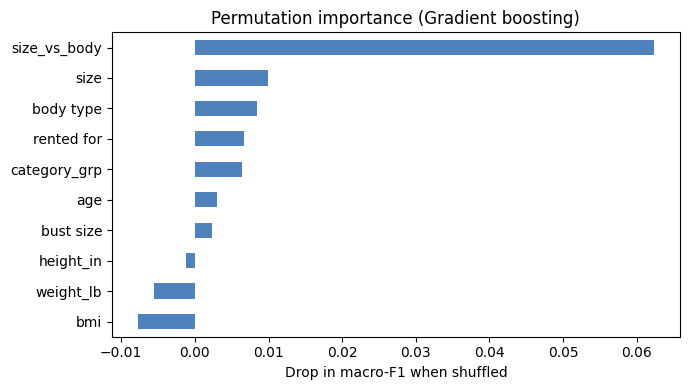

size_vs_body    0.0624
size            0.0100
body type       0.0085
rented for      0.0067
category_grp    0.0064
age             0.0031
bust size       0.0023
height_in      -0.0012
weight_lb      -0.0055
bmi            -0.0078
dtype: float64


In [11]:
# What drives fit mismatch? Permutation importance on the best model (macro-F1 scoring)
best_name = metrics_df[metrics_df.model != "Baseline (always 'fit')"].sort_values("auc_ovr").iloc[-1]["model"]
best = fitted[best_name]
sub = X_te.sample(min(4000, len(X_te)), random_state=0)
pi = permutation_importance(best, sub, y_te.loc[sub.index], n_repeats=5, random_state=0, scoring="f1_macro")
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color="#4f81bd")
ax.set_title(f"Permutation importance ({best_name})"); ax.set_xlabel("Drop in macro-F1 when shuffled")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_feature_importance.png", dpi=150); plt.show()
print(imp.round(4).sort_values(ascending=False))

## 8. Findings into sizing recommendations
Rules:
- **Grade up / size-up note:** cell is significantly above overall "runs small" rate.
- **Grade down / size-down note:** cell is significantly above overall "runs large" rate.
- **Length review:** tall reviewers say "too short" at >= 10% and at 2x+ the rate of short reviewers.
  Suggests a tall option or longer hem.
- Cost estimates use clearly labeled assumptions below and cover only the reviews in this dataset.

In [12]:
# --- Assumptions (edit these; they are illustrative, NOT from the dataset) ---
RETURN_RATE_GIVEN_MISMATCH = 0.30   # share of fit-mismatch customers who would return the item
COST_PER_RETURN = 18.0              # shipping + processing + cleaning, dollars
# Costs below are for the reviews in this dataset only. Scale by your own review-to-order ratio.

recs = []
for _, r in by_cell[by_cell.flag_small | by_cell.flag_large].iterrows():
    direction = "small" if r.flag_small and (not r.flag_large or r.small_rate >= r.large_rate) else "large"
    excess = (r.small_rate - overall["is_small"]) if direction == "small" else (r.large_rate - overall["is_large"])
    action = ("Add fit note 'runs small, consider sizing up'; review grade rules for this size"
              if direction == "small" else
              "Add fit note 'runs large, consider sizing down'; review grade rules for this size")
    recs.append({"category": r.category_grp, "size_bucket": r.size_bucket, "reviews": int(r.n),
                 "direction": direction, "rate": r.small_rate if direction == "small" else r.large_rate,
                 "excess_vs_overall": excess, "action": action,
                 "excess_mismatch_reviews": excess * r.n,
                 "est_cost_of_excess": excess * r.n * RETURN_RATE_GIVEN_MISMATCH * COST_PER_RETURN})
for _, r in h_wide.iterrows():
    tall_short, short_short = r["short_txt_tall"], r["short_txt_short"]
    if tall_short >= 0.10 and short_short > 0 and tall_short / short_short >= 2:
        recs.append({"category": r["category_grp"], "size_bucket": "all (tall)", "reviews": int(r["n_tall"]),
                     "direction": "length", "rate": tall_short,
                     "excess_vs_overall": tall_short - short_short,
                     "action": "Offer a tall/long length option or lengthen hem: tall reviewers say it is too short at 2x+ the rate of short reviewers",
                     "excess_mismatch_reviews": np.nan, "est_cost_of_excess": np.nan})
recs_df = pd.DataFrame(recs).sort_values("excess_vs_overall", ascending=False)
print(f"{len(recs_df)} recommendations")
recs_df.round(3).head(15)

63 recommendations


,category,size_bucket,reviews,direction,rate,excess_vs_overall,action,excess_mismatch_reviews,est_cost_of_excess
2,coat,4-6 (S),182,large,0.462,0.333,"Add fit note 'runs large, consider sizing down...",60.646,327.488
7,down,4-6 (S),93,large,0.419,0.291,"Add fit note 'runs large, consider sizing down...",27.066,146.158
25,mini,16-20 (XL),248,small,0.415,0.281,"Add fit note 'runs small, consider sizing up';...",69.796,376.899
4,coat,12-14 (L),257,large,0.346,0.218,"Add fit note 'runs large, consider sizing down...",56.022,302.519
3,coat,8-10 (M),271,large,0.332,0.204,"Add fit note 'runs large, consider sizing down...",55.226,298.218
5,coat,16-20 (XL),191,large,0.330,0.202,"Add fit note 'runs large, consider sizing down...",38.491,207.852
32,pants,8-10 (M),118,large,0.305,0.177,"Add fit note 'runs large, consider sizing down...",20.858,112.635
45,shirtdress,4-6 (S),150,large,0.293,0.165,"Add fit note 'runs large, consider sizing down...",24.752,133.662
27,other,4-6 (S),634,large,0.290,0.162,"Add fit note 'runs large, consider sizing down...",102.646,554.288
8,down,8-10 (M),157,large,0.280,0.152,"Add fit note 'runs large, consider sizing down...",23.854,128.811


## 9. Export for Tableau and the write-up

In [13]:
by_cat.to_csv(f"{OUT_DIR}/fit_by_category.csv", index=False)
by_cell.to_csv(f"{OUT_DIR}/fit_by_category_size.csv", index=False)
h_wide.to_csv(f"{OUT_DIR}/height_effects_by_category.csv", index=False)
metrics_df.to_csv(f"{OUT_DIR}/model_metrics.csv", index=False)
svb.to_csv(f"{OUT_DIR}/fit_by_size_vs_body.csv", index=False)
recs_df.to_csv(f"{OUT_DIR}/sizing_recommendations.csv", index=False)

top_cat = by_cat.iloc[0]
summary = f"""
FIT ANALYSIS SUMMARY (Rent the Runway)
Reviews analyzed: {len(df):,} | Categories: {df.category_grp.nunique()} | Overall mismatch rate: {overall['mismatch']:.1%}
  (runs small {overall['is_small']:.1%}, runs large {overall['is_large']:.1%})
Highest-mismatch category: {top_cat.category_grp} ({top_cat.mismatch_rate:.1%}, n={int(top_cat.n):,})
Category x size cells flagged for elevated mismatch: {int(by_cell.flag_mismatch.sum())} of {len(by_cell)}
Best model: {best_name} (macro-F1 {metrics_df.set_index('model').loc[best_name,'macro_f1']:.3f},
  AUC {metrics_df.set_index('model').loc[best_name,'auc_ovr']:.3f})
Recommendations generated: {len(recs_df)}
"""
print(summary)
open(f"{OUT_DIR}/summary.txt", "w").write(summary)


FIT ANALYSIS SUMMARY (Rent the Runway)
Reviews analyzed: 192,544 | Categories: 19 | Overall mismatch rate: 26.2%
  (runs small 13.4%, runs large 12.8%)
Highest-mismatch category: coat (40.4%, n=980)
Category x size cells flagged for elevated mismatch: 25 of 104
Best model: Gradient boosting (macro-F1 0.373,
  AUC 0.652)
Recommendations generated: 63



353